1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


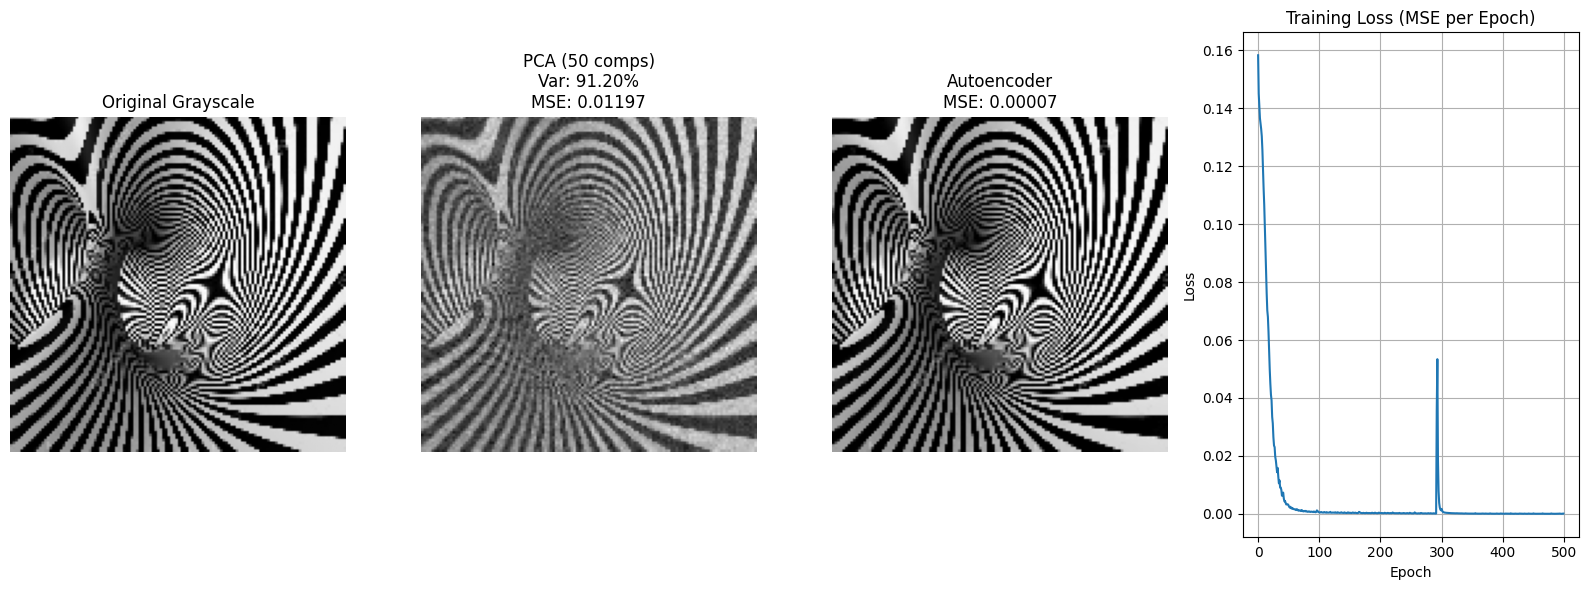

==== Perbandingan Kinerja ====
PCA Explained Variance : 91.20%
PCA MSE Rekonstruksi   : 0.011972
Autoencoder MSE        : 0.000066

✅ Autoencoder lebih unggul dalam merekonstruksi gambar (error lebih kecil).


In [4]:
# ============================================================
# 📘 Perbandingan PCA vs Autoencoder untuk Kompresi Gambar
# Tujuan: Membuktikan Autoencoder lebih unggul (MSE lebih kecil)
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from tensorflow.keras import layers, models

# --- Step 1: Load dan Preprocessing Gambar ---
image_path = '/content/spiral.jpg'  # ganti dengan path gambar kamu
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (128, 128))
img = img.astype('float32') / 255.0

# Gunakan grayscale agar mudah dibandingkan
gray = cv2.cvtColor((img * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
gray = gray / 255.0

# --- Step 2: PCA Reconstruction ---
def apply_pca(image, n_components=50):
    pca = PCA(n_components=n_components)
    transformed = pca.fit_transform(image)
    reconstructed = pca.inverse_transform(transformed)
    return reconstructed, pca.explained_variance_ratio_.sum()

pca_reconstructed, pca_var = apply_pca(gray, n_components=50)

# --- Step 3: Autoencoder Architecture (Deeper) ---
input_img = layers.Input(shape=(128, 128, 1))

# Encoder
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x) # Added layer and increased filters
x = layers.MaxPooling2D((2, 2), padding='same')(x)
encoded = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x) # Increased filters

# Decoder
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(encoded) # Increased filters
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x) # Added layer and increased filters
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = models.Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='mse')

# --- Step 4: Dataset Simulasi dari Satu Gambar ---
gray_expanded = np.expand_dims(gray, axis=(0, -1))
data = np.repeat(gray_expanded, 100, axis=0)

# --- Step 5: Training ---
history = autoencoder.fit(data, data, epochs=500, batch_size=10, verbose=0)

# --- Step 6: Reconstruction dari Autoencoder ---
autoencoded_img = autoencoder.predict(np.expand_dims(gray, axis=(0, -1)))[0, :, :, 0]

# --- Step 7: Hitung MSE ---
pca_mse = mean_squared_error(gray.flatten(), pca_reconstructed.flatten())
ae_mse = mean_squared_error(gray.flatten(), autoencoded_img.flatten())

# --- Step 8: Visualisasi ---
plt.figure(figsize=(16,6))

plt.subplot(1,4,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(pca_reconstructed, cmap='gray')
plt.title(f"PCA (50 comps)\nVar: {pca_var*100:.2f}%\nMSE: {pca_mse:.5f}")
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(autoencoded_img, cmap='gray')
plt.title(f"Autoencoder\nMSE: {ae_mse:.5f}")
plt.axis('off')

# Plot loss training
plt.subplot(1,4,4)
plt.plot(history.history['loss'])
plt.title("Training Loss (MSE per Epoch)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.tight_layout()
plt.show()

# --- Step 9: Hasil Numerik ---
print("==== Perbandingan Kinerja ====")
print(f"PCA Explained Variance : {pca_var*100:.2f}%")
print(f"PCA MSE Rekonstruksi   : {pca_mse:.6f}")
print(f"Autoencoder MSE        : {ae_mse:.6f}")

if ae_mse < pca_mse:
    print("\n✅ Autoencoder lebih unggul dalam merekonstruksi gambar (error lebih kecil).")
else:
    print("\n⚠️ PCA masih unggul — coba tambah epoch atau ubah layer Autoencoder.")